In [2]:

from pathlib import Path
import pandas as pd

project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

pm25 = pd.read_csv(
    project_dir / "data/processed/pm25_cleaned.csv",
    dtype={
        "State Code": str,
        "County Code": str,
        "Site Num": str
    }
)

pm25["station_id"] = (
    pm25["State Code"].str.zfill(2)
    + "-"
    + pm25["County Code"].str.zfill(3)
    + "-"
    + pm25["Site Num"].str.zfill(4)
)


In [3]:

import requests
import pandas as pd

# Mono County EPA monitoring station
# Station identifier: 06-051-0005

# Obtain exact coordinates from our cleaned EPA data
mono_station = pm25[
    pm25["station_id"] == "06-051-0005"
][["Latitude", "Longitude"]].iloc[0]

latitude = float(mono_station["Latitude"])
longitude = float(mono_station["Longitude"])

print("Latitude:", latitude)
print("Longitude:", longitude)

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": latitude,
    "longitude": longitude,
    "start_date": "2025-09-01",
    "end_date": "2025-09-15",
    "hourly": [
        "temperature_2m",
        "relative_humidity_2m",
        "precipitation",
        "wind_speed_10m",
        "wind_direction_10m"
    ],
    "timezone": "America/Los_Angeles"
}

response = requests.get(
    url,
    params=params,
    timeout=60
)

response.raise_for_status()

weather_data = response.json()

weather = pd.DataFrame(
    weather_data["hourly"]
)

display(weather.head())

print("Total hourly records:", len(weather))


Latitude: 37.962069
Longitude: -119.120278


,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,wind_direction_10m
0,2025-09-01T00:00,14.8,78,0.0,4.8,290
1,2025-09-01T01:00,14.6,74,0.0,3.6,290
2,2025-09-01T02:00,14.6,69,0.0,2.4,287
3,2025-09-01T03:00,14.7,63,0.0,1.7,283
4,2025-09-01T04:00,15.3,57,0.0,1.1,270


Total hourly records: 360


In [4]:

# Convert time strings to datetime
weather["time"] = pd.to_datetime(weather["time"])

# Extract date
weather["date"] = weather["time"].dt.normalize()

print("Total weather records:", len(weather))

print("Date range:")
print(weather["time"].min())
print(weather["time"].max())

print("\nMissing values:")
print(weather.isna().sum())


Total weather records: 360
Date range:
2025-09-01 00:00:00
2025-09-15 23:00:00

Missing values:
time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
wind_speed_10m          0
wind_direction_10m      0
date                    0
dtype: int64


In [5]:

import numpy as np

# Wind direction in radians
angle = np.deg2rad(weather["wind_direction_10m"])

# Unit vectors representing direction
weather["wind_sin"] = np.sin(angle)
weather["wind_cos"] = np.cos(angle)

daily_weather = (
    weather.groupby("date")
    .agg(
        temperature_mean=("temperature_2m", "mean"),
        humidity_mean=("relative_humidity_2m", "mean"),
        wind_speed_mean=("wind_speed_10m", "mean"),
        precipitation_total=("precipitation", "sum"),
        wind_sin_mean=("wind_sin", "mean"),
        wind_cos_mean=("wind_cos", "mean")
    )
    .reset_index()
)

# Circular mean wind direction
daily_weather["wind_direction_mean"] = (
    np.rad2deg(
        np.arctan2(
            daily_weather["wind_sin_mean"],
            daily_weather["wind_cos_mean"]
        )
    ) % 360
)

display(daily_weather)


,date,temperature_mean,humidity_mean,wind_speed_mean,precipitation_total,wind_sin_mean,wind_cos_mean,wind_direction_mean
0,2025-09-01,19.366667,48.208333,4.050000,0.0,-0.173629,0.160463,312.743333
1,2025-09-02,18.504167,50.000000,4.754167,0.4,-0.361663,0.127423,289.408708
2,2025-09-03,17.816667,55.625000,3.850000,0.0,-0.190751,0.135667,305.421282
3,2025-09-04,17.983333,54.541667,5.216667,0.1,-0.256584,0.287976,318.299226
4,2025-09-05,17.504167,51.250000,3.650000,0.2,-0.160115,-0.019321,263.119503
5,2025-09-06,17.733333,42.833333,7.562500,0.0,-0.020966,-0.384151,183.123978
6,2025-09-07,16.450000,38.958333,6.087500,0.0,-0.227176,-0.291884,217.893937
7,2025-09-08,15.912500,36.541667,5.991667,0.0,-0.138316,-0.230173,211.002547
8,2025-09-09,14.750000,49.375000,6.608333,0.0,-0.306231,-0.266510,228.967296
9,2025-09-10,12.175000,56.208333,5.441667,1.7,-0.185855,0.300459,328.260365


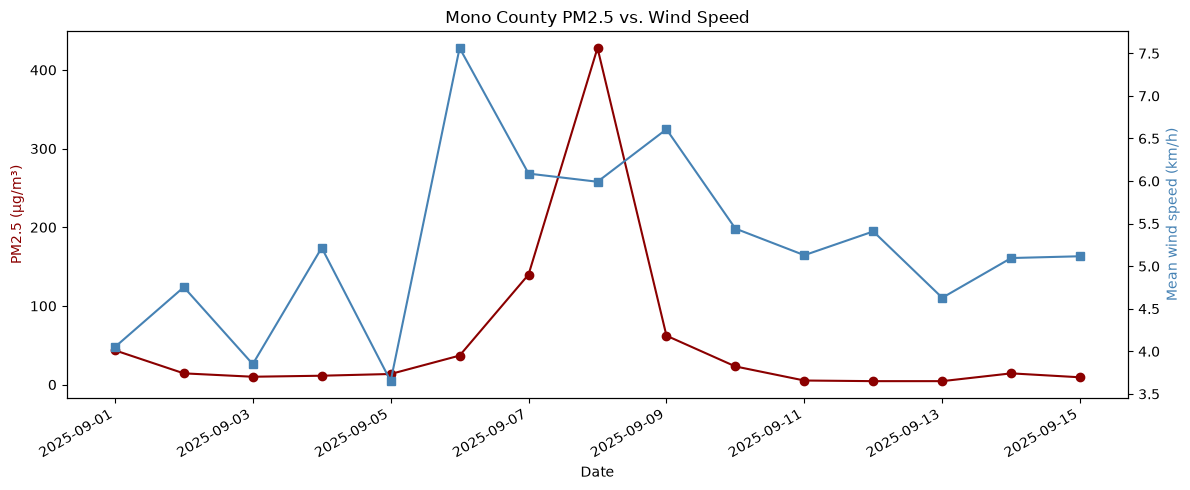

In [6]:

import matplotlib.pyplot as plt

# Read the cleaned EPA dataset already loaded as pm25
mono_pm25 = pm25[
    pm25["station_id"] == "06-051-0005"
].copy()

mono_pm25["Date Local"] = pd.to_datetime(
    mono_pm25["Date Local"]
)

# Join daily weather with PM2.5
event_weather = daily_weather.merge(
    mono_pm25[
        ["Date Local", "Arithmetic Mean"]
    ],
    left_on="date",
    right_on="Date Local",
    how="left"
)

fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(
    event_weather["date"],
    event_weather["Arithmetic Mean"],
    marker="o",
    color="darkred"
)

ax1.set_ylabel("PM2.5 (µg/m³)", color="darkred")
ax1.set_xlabel("Date")

ax2 = ax1.twinx()

ax2.plot(
    event_weather["date"],
    event_weather["wind_speed_mean"],
    marker="s",
    color="steelblue"
)

ax2.set_ylabel("Mean wind speed (km/h)", color="steelblue")

plt.title("Mono County PM2.5 vs. Wind Speed")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [10]:

# Focus on the pollution event
event_days = daily_weather[
    daily_weather["date"].between(
        "2025-09-06",
        "2025-09-10"
    )
].copy()

display(
    event_days.style.format({
        "temperature_mean": "{:.2f}",
        "humidity_mean": "{:.2f}",
        "wind_speed_mean": "{:.2f}",
        "wind_direction_mean": "{:.2f}",
        "precipitation_total": "{:.2f}"
    })
)


,date,temperature_mean,humidity_mean,wind_speed_mean,precipitation_total,wind_sin_mean,wind_cos_mean,wind_direction_mean
5,2025-09-06 00:00:00,17.73,42.83,7.56,0.00,-0.020966,-0.384151,183.12
6,2025-09-07 00:00:00,16.45,38.96,6.09,0.00,-0.227176,-0.291884,217.89
7,2025-09-08 00:00:00,15.91,36.54,5.99,0.00,-0.138316,-0.230173,211.00
8,2025-09-09 00:00:00,14.75,49.38,6.61,0.00,-0.306231,-0.266510,228.97
9,2025-09-10 00:00:00,12.17,56.21,5.44,1.70,-0.185855,0.300459,328.26


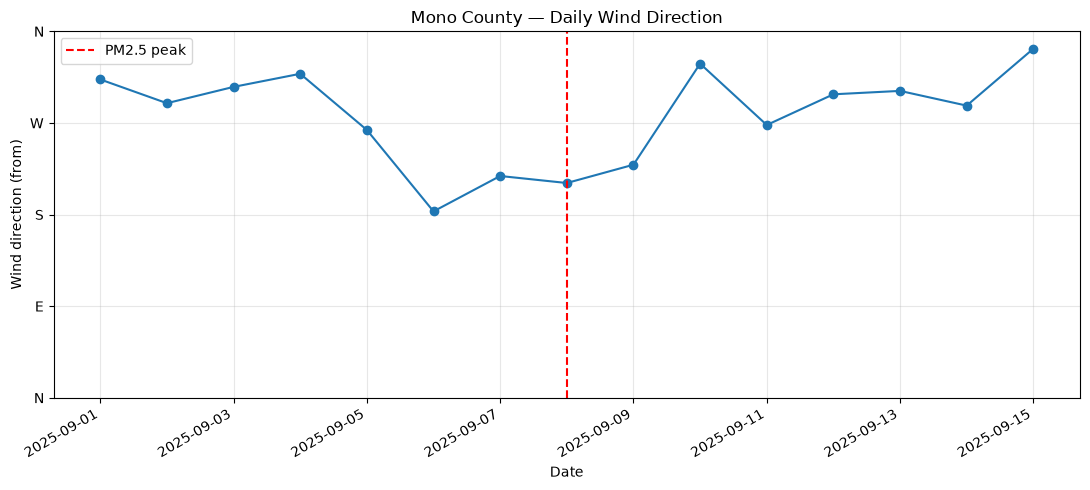

In [8]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    daily_weather["date"],
    daily_weather["wind_direction_mean"],
    marker="o"
)

ax.axvline(
    pd.Timestamp("2025-09-08"),
    linestyle="--",
    color="red",
    label="PM2.5 peak"
)

ax.set_yticks([0, 90, 180, 270, 360])
ax.set_yticklabels(["N", "E", "S", "W", "N"])

ax.set_ylabel("Wind direction (from)")
ax.set_xlabel("Date")
ax.set_title("Mono County — Daily Wind Direction")
ax.legend()
ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [9]:

from pathlib import Path

output_dir = project_dir / "data/processed"
output_dir.mkdir(parents=True, exist_ok=True)

# Save hourly observations
weather.to_csv(
    output_dir / "mono_weather_hourly.csv",
    index=False
)

# Save daily summaries
daily_weather.to_csv(
    output_dir / "mono_weather_daily.csv",
    index=False
)

print("Weather datasets saved successfully!")


Weather datasets saved successfully!
